<a href="https://colab.research.google.com/github/mahd1-design/Chest-Xray-Pneumonia-Detection/blob/main/chest_xray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset location:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset location: /kaggle/input/chest-xray-pneumonia


In [3]:
import os

print(os.listdir(path))

['chest_xray']


In [7]:
data_dir = os.path.join(path, "chest_xray")

train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

print(" Training folders", os.listdir(train_dir))
print("Testing folders", os.listdir(test_dir))




 Training folders ['PNEUMONIA', 'NORMAL']
Testing folders ['PNEUMONIA', 'NORMAL']


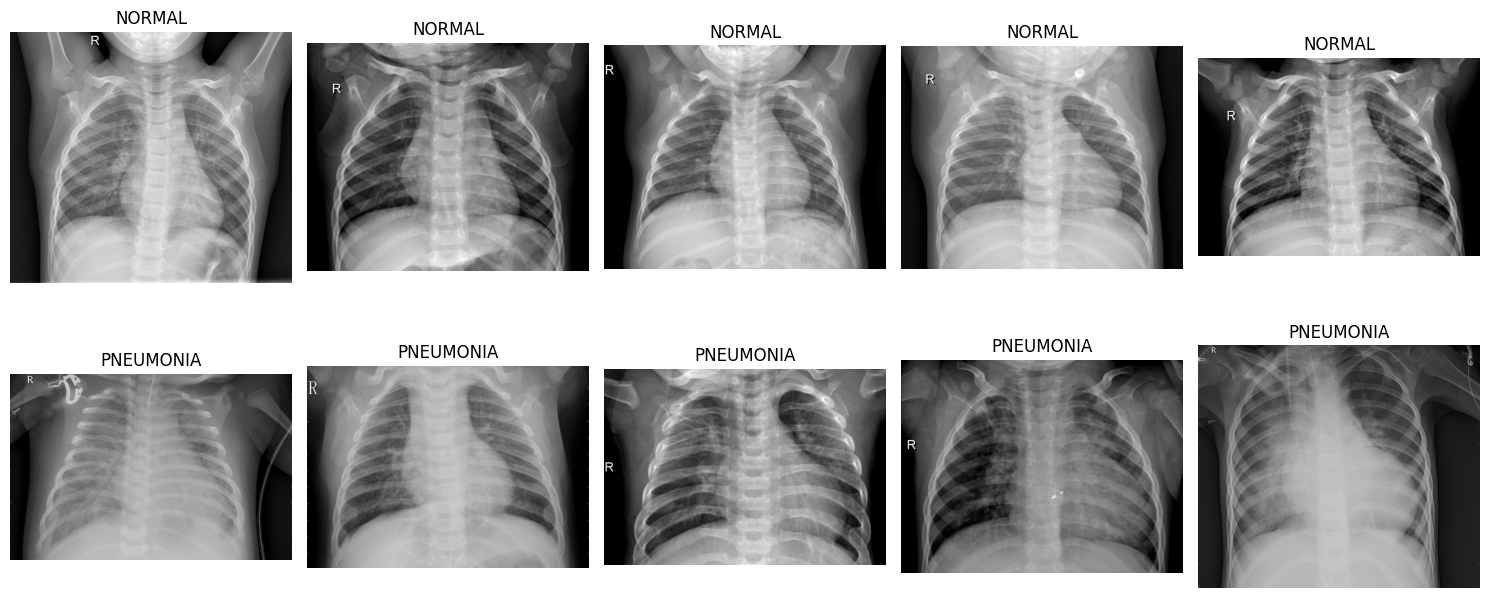

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

classes = ["NORMAL", "PNEUMONIA"]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, class_name in enumerate(classes):

    folder = os.path.join(train_dir, class_name)

    images = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpeg", ".jpg", ".png"))
    ])[:5]

    for j, filename in enumerate(images):

        image = Image.open(os.path.join(folder, filename))

        axes[i, j].imshow(image, cmap="gray")
        axes[i, j].set_title(class_name)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [11]:
for  class_name in classes:
  folder = os.path.join(train_dir, class_name)

  count = len([
      f for f in os.listdir(folder)
      if f.lower().endswith((".jpeg", ".jpg","png"))
      ])
  print(class_name, "images:", count)

NORMAL images: 1341
PNEUMONIA images: 3875


In [12]:
import tensorflow as tf
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size =32
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size =(224,224),
    batch_size = 32
)

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


In [15]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_dataset = train_dataset.map(
    lambda images, labels : (normalization_layer(images), labels)
)
test_dataset = test_dataset.map(
    lambda images, labels :(normalization_layer(images), labels)
)


In [16]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.05)
])

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(
    train_dataset,
    epochs = 10
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 57s 294ms/step - accuracy: 0.7431 - loss: 0.5802
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 34s 210ms/step - accuracy: 0.7429 - loss: 0.5785
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 40s 207ms/step - accuracy: 0.7429 - loss: 0.5727
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 208ms/step - accuracy: 0.7429 - loss: 0.5733
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 34s 207ms/step - accuracy: 0.7429 - loss: 0.5712
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 208ms/step - accuracy: 0.7429 - loss: 0.5745
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 208ms/step - accuracy: 0.7429 - loss: 0.5736
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 34s 208ms/step - accuracy: 0.7429 - loss: 0.5745
Epoch 9/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 50s 266ms/step - accuracy: 0.7429 - loss: 0.5718
Epoch 10/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 40s 244ms/step - accuracy: 0.7429 - loss: 0.5714


In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
y_true= []
y_pred = []
for images, labels in test_dataset:
  predictions = model.predict(images, verbose=0)
  predicted_labels = (predictions > 0.5). astype(int). flatten()
  y_true.extend(labels.numpy())
  y_pred.extend(predicted_labels)
print("Accuracy:" , accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1-score:", f1_score(y_true, y_pred))

Accuracy: 0.625
Precision: 0.625
Recall: 1.0
F1-score: 0.7692307692307693


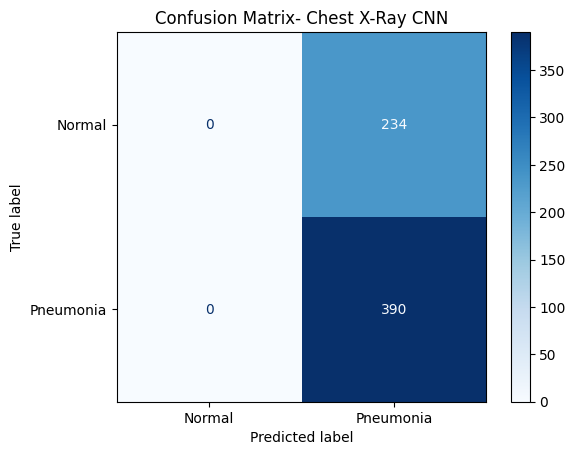

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_true,y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels = ["Normal", "Pneumonia"]
)
display.plot(cmap="Blues")
plt.title("Confusion Matrix- Chest X-Ray CNN"),
plt.show()

In [27]:
print("Training accuracy:", history.history["accuracy"][-1])
print("Training loss:", history.history ["loss"][-1])

Training accuracy: 0.7429064512252808
Training loss: 0.5713841915130615


In [28]:
val_dir =os.path.join(data_dir , "val")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(224,224),
    batch_size =32
)
val_dataset =val_dataset.map(
    lambda images, labels: (normalization_layer(images), labels)
)

Found 16 files belonging to 2 classes.


In [30]:
history= model.fit (
    train_dataset,
    validation_data =val_dataset,
    epochs=10
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 360ms/step - accuracy: 0.7429 - loss: 0.5737 - val_accuracy: 0.4375 - val_loss: 0.6940
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 53s 324ms/step - accuracy: 0.7429 - loss: 0.5719 - val_accuracy: 0.5000 - val_loss: 0.6939
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 70s 252ms/step - accuracy: 0.7429 - loss: 0.5731 - val_accuracy: 0.5000 - val_loss: 0.6938
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 228ms/step - accuracy: 0.7429 - loss: 0.5720 - val_accuracy: 0.5000 - val_loss: 0.6938
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 222ms/step - accuracy: 0.7429 - loss: 0.5729 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 223ms/step - accuracy: 0.7429 - loss: 0.5734 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 222ms/step - accuracy: 0.7429 - loss: 0.5716 - val_accuracy: 0.4375 - val_loss: 0.6937
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 221ms/step - accuracy: 0.7429 - loss: 0

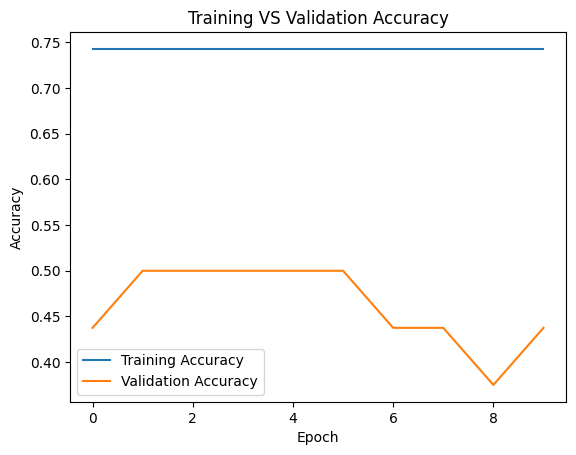

In [31]:
plt.plot(history.history["accuracy"], label ="Training Accuracy")
plt.plot(history.history["val_accuracy"], label ="Validation Accuracy")

plt.title ("Training VS Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

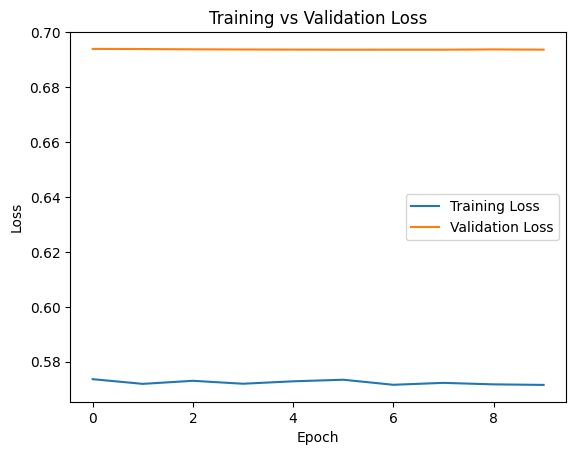

In [32]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()